# Primer trabajo biofísica
## Pablo Duarte López

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn import datasets
from sklearn import preprocessing
from sklearn import linear_model
from sklearn import model_selection as ms
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import classification_report, confusion_matrix, balanced_accuracy_score
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

df= pd.read_csv("sleep_debt_screen_time.csv")
df

,user_id,age,gender,chronotype,occupation,bedtime_hour,screen_time_before_bed_min,primary_app_category,screen_brightness_pct,blue_light_filter_on,...,room_temperature_f,ambient_noise_db,sleep_onset_latency_min,total_sleep_hours,rem_sleep_pct,deep_sleep_pct,awakenings_count,sleep_efficiency_pct,next_day_fatigue_score,sleep_debt_category
0,1,32,Female,Intermediate,Student,23.94,102,Social Media,100,False,...,73.5,32.6,60.3,5.67,15.2,13.5,11,63.7,8.85,Moderate
1,2,26,Female,Intermediate,Student,0.06,14,Short-Form Video,87,True,...,66.8,44.3,24.5,7.42,16.9,22.3,1,92.9,2.98,No Debt
2,3,34,Male,Night Owl,Professional,1.48,58,Messaging,76,True,...,68.0,45.6,21.9,6.98,20.2,18.5,2,84.6,3.90,Mild
3,4,43,Female,Intermediate,Professional,22.42,48,Social Media,56,False,...,72.3,42.3,34.5,7.67,14.4,17.3,6,79.9,4.81,No Debt
4,5,25,Male,Early Bird,Professional,22.43,29,Streaming,96,True,...,80.1,10.0,37.4,6.31,16.6,16.1,0,89.3,3.88,Mild
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8495,8496,35,Male,Early Bird,Retired,22.16,76,Gaming,83,False,...,68.0,16.1,33.8,6.57,15.5,14.0,3,81.7,4.96,Mild
8496,8497,33,Female,Intermediate,Freelancer,23.14,102,E-Reading,55,False,...,71.1,41.0,14.8,7.00,20.3,20.4,2,81.9,4.06,Mild
8497,8498,40,Female,Intermediate,Student,0.76,52,Streaming,87,True,...,71.9,41.2,16.8,6.51,17.3,17.2,0,77.8,4.27,Mild
8498,8499,16,Male,Night Owl,Student,1.60,53,Gaming,72,True,...,67.2,23.5,25.6,7.47,12.4,18.7,3,87.3,4.49,Mild


## DATA CLEANSING
Antes de comenzar este trabajo hemos estudiado las características de nuestra base de datos. Vemos que no contiene absolutamente ningún valor Nan, ni filas repetidas, por lo que en un principio no debería ser necesario hacer un proceso exhaustivo de data cleaning. De todos modos, va a ser interesante para nosotros hacer unas modificaciones con el fin de tratar de mejor forma los datos. Vemos que:

sleep_debt_category
Mild        4393
Moderate    2386
No Debt     1721
Name: count, dtype: int64


<BarContainer object of 3 artists>

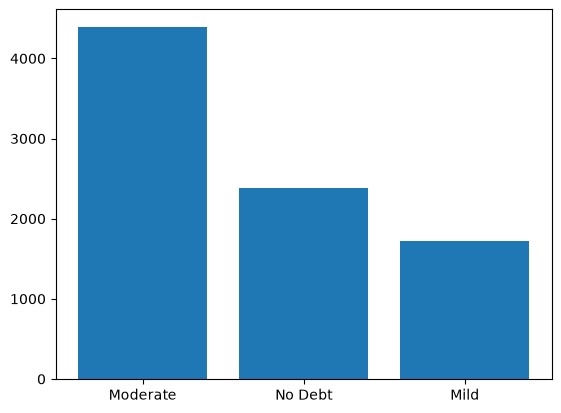

In [55]:
print(df["sleep_debt_category"].value_counts())
plt.bar(df["sleep_debt_category"].unique(), df["sleep_debt_category"].value_counts())

Vemos que el número de personas en la categoría: "Severe" es ínfimo comparado con el resto, por lo que la vamos a eliminar por completo y reasignarles la categoría "Moderate", que sería la siguiente en el gradiente de "sleep debt"

sleep_debt_category
Mild        4393
Moderate    2386
No Debt     1721
Name: count, dtype: int64


<BarContainer object of 3 artists>

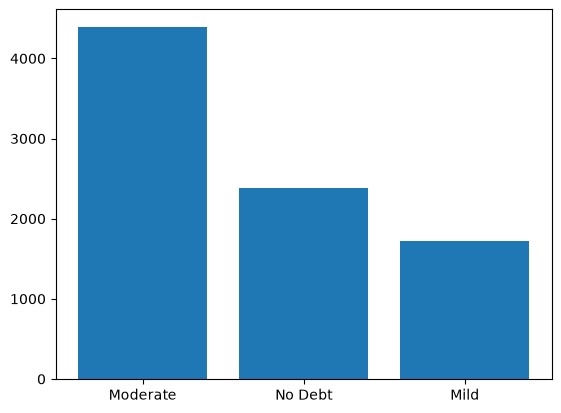

In [56]:
df.loc[df["sleep_debt_category"] == "Severe", "sleep_debt_category"] = "Moderate"
print(df["sleep_debt_category"].value_counts())
plt.bar(df["sleep_debt_category"].unique(), df["sleep_debt_category"].value_counts())

Aún así, la diferencia entre las distintas categorías no es despreciable. Vamos a hacer un resampling para que todas las categorías tengan la misma cantidad de personas. Esto será de vital importancia a la hora de eliminar sesgos en nuestras clasificaciones

<BarContainer object of 3 artists>

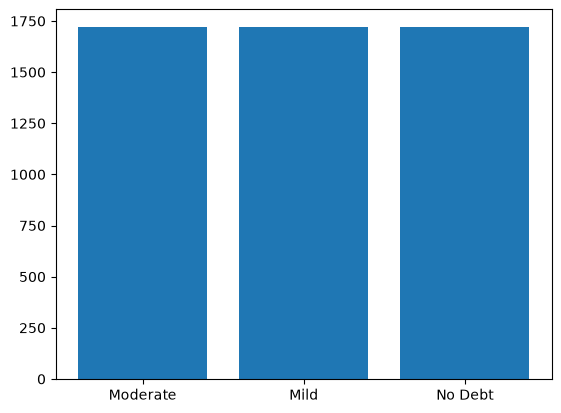

In [57]:
df_mild = df[df['sleep_debt_category'] == 'Mild']
df_moderate = df[df['sleep_debt_category'] == 'Moderate']
df_no = df[df['sleep_debt_category'] == 'No Debt']

df_moderate_reduced = df_moderate.sample(1721,random_state=6769420)
df_mild_reduced = df_mild.sample(1721,random_state=6769420)
df_reduced = pd.concat([df_moderate_reduced,df_mild_reduced,df_no],axis=0)

plt.bar(df_reduced["sleep_debt_category"].unique(), df_reduced["sleep_debt_category"].value_counts())

## Clasificación usando un árbol de regresión
Haremos dos experimentos. El primero será intentar clasificar el nivel de "sleep debt" de los usuarios según sus características (edad, género, cronotipo, ocupación). Posteriormente los clasificaremos según sus hábitos (hora de irse a dormir, tiempo de pantalla antes de dormir, tipo de aplicación usada antes de dormir, etc...). Intenaremos ver si son más importantes las características de los individuos o sus hábitos a la hora de clasificarlos, así como también haremos un árbol empleando ambos tipos de datos para ver como de bien podemos llegar a clasificar a los distintos individuos.

### Clasificación según características de los individuos
Para esta sección, voy a hacer la clasificación de dos formas: primero, empleando el dataframe reducido antes definido y, después, empleando una clasificación en arbol con un peso por clase balanceado (class_weight= 'balanced'). Compararemos los resultados y usaremos para el resto de nuestro análisis el mejor de ellos

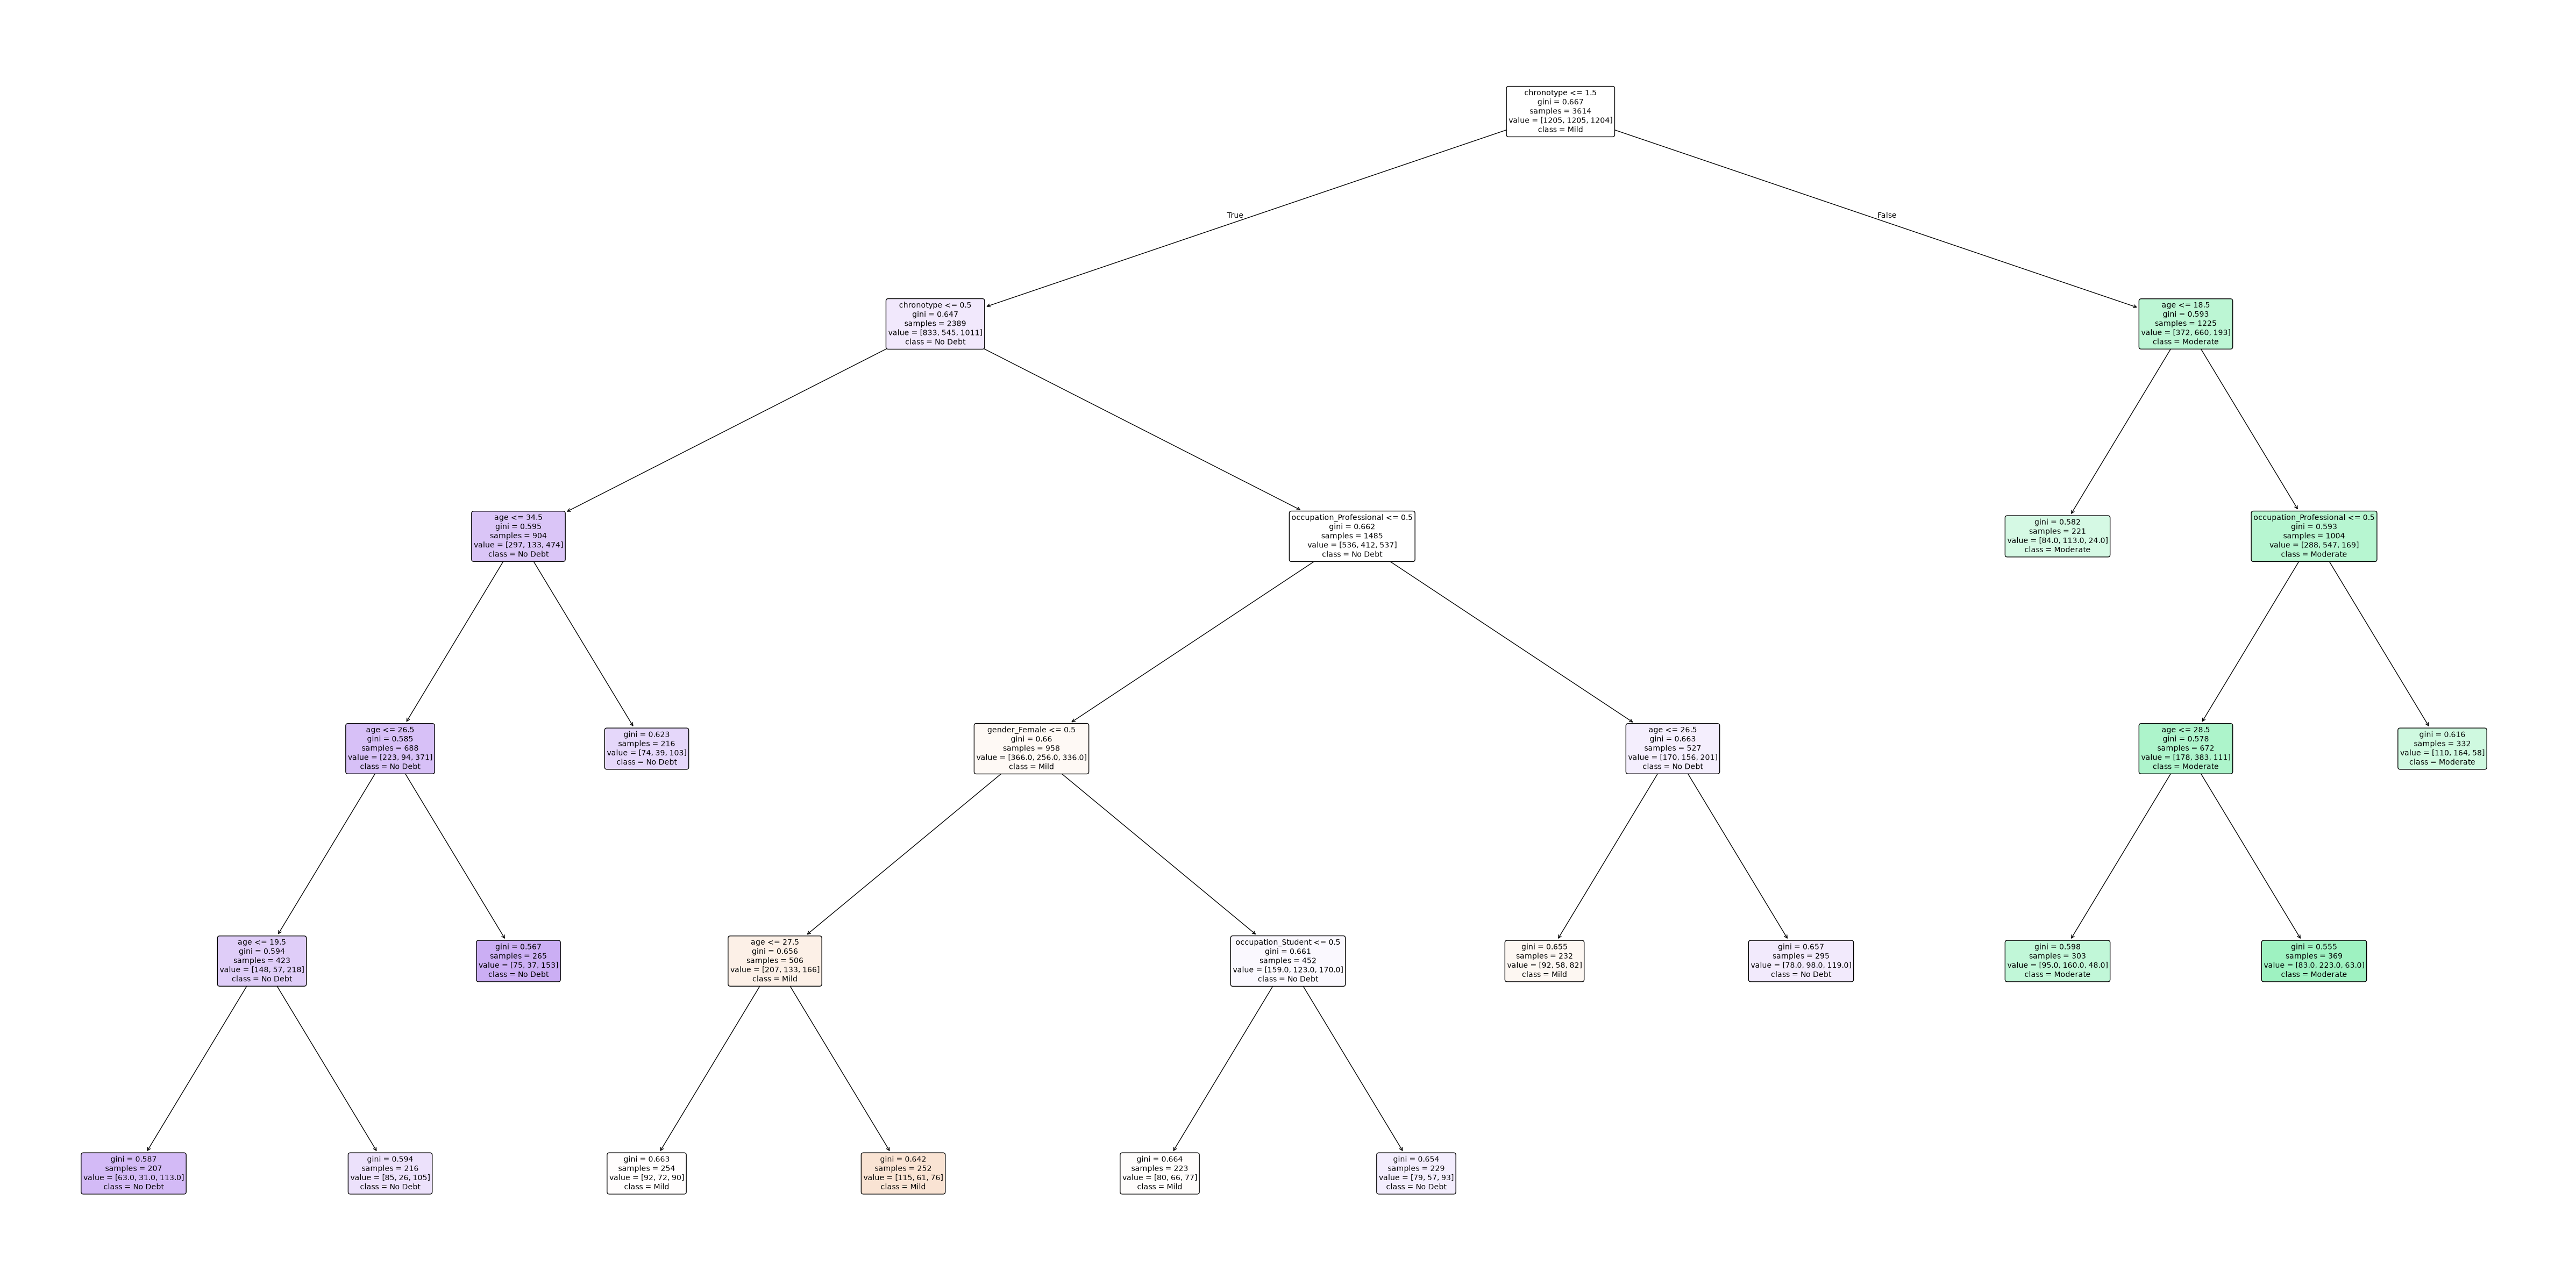

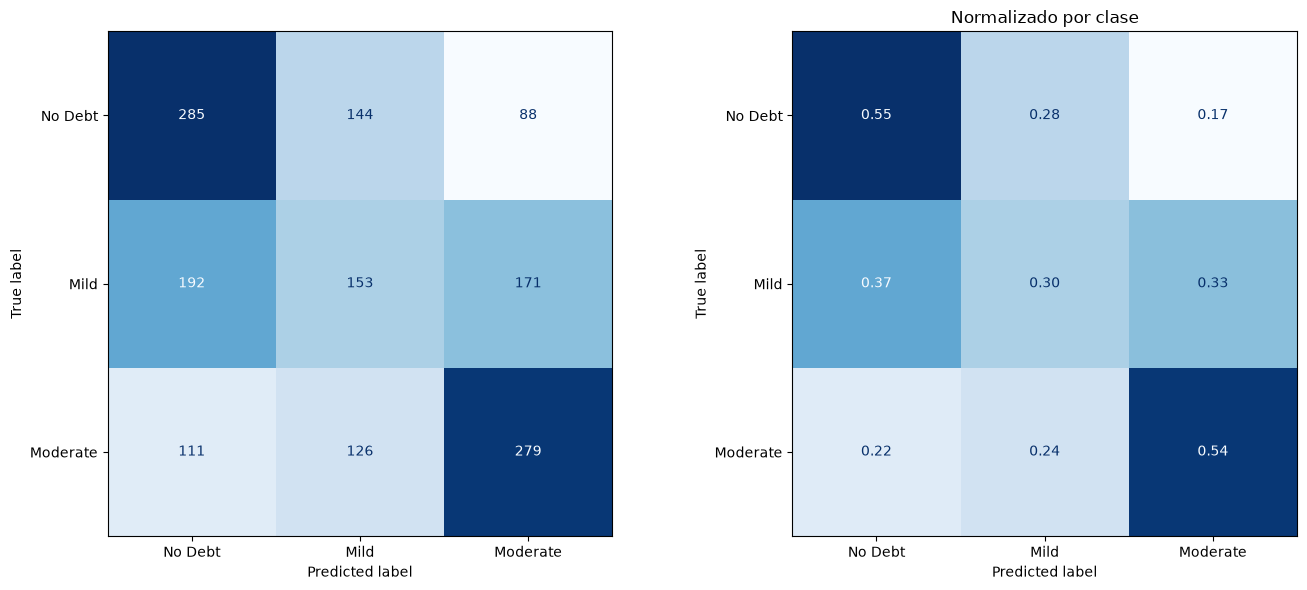

              precision    recall  f1-score   support

     No Debt       0.48      0.55      0.52       517
        Mild       0.36      0.30      0.33       516
    Moderate       0.52      0.54      0.53       516

    accuracy                           0.46      1549
   macro avg       0.45      0.46      0.46      1549
weighted avg       0.46      0.46      0.46      1549



In [53]:
#Columnas con los datos que usaremos para la clasificación
X = df_reduced[["gender", "chronotype","occupation","age"]].copy() 
X["chronotype"] = X["chronotype"].map({"Early Bird": 0, "Intermediate": 1, "Night Owl": 2}) #Pasamos los valores de categóricos a numerales ordenados
X = pd.get_dummies(X, columns=["gender","occupation"]) 
y = df_reduced["sleep_debt_category"]

#Una vez definidas las categorías en las que clasificar y los criterios que se tomarán en cuenta, podemos crear el árbol


#Dividimos en test y entrenamiento
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=3, stratify=y
)


tree = DecisionTreeClassifier(
    criterion="gini",
    max_depth=5,
    min_samples_leaf=200,
    random_state=6769420,
)

tree.fit(X_train, y_train)
pred = tree.predict(X_test)



fig, ax = plt.subplots(figsize=(48, 24))
plot_tree(
    tree,
    feature_names=X.columns,
    class_names=[str(c) for c in tree.classes_],
    filled=True, rounded=True, fontsize=10, ax=ax,
)
plt.tight_layout()



#################################################3
#Matriz de confusión

cm = confusion_matrix(y_test, pred, labels=["No Debt", "Mild", "Moderate"])

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

ConfusionMatrixDisplay.from_predictions(y_test, pred, labels=order, ax=axes[0], cmap="Blues", colorbar=False)

ConfusionMatrixDisplay.from_predictions(
    y_test, pred, labels=order, normalize="true", values_format=".2f",
    ax=axes[1], cmap="Blues", colorbar=False
)
axes[1].set_title("Normalizado por clase")

plt.tight_layout()
plt.show()

print(classification_report(y_test, pred, labels=order, zero_division=0))

plt.show()

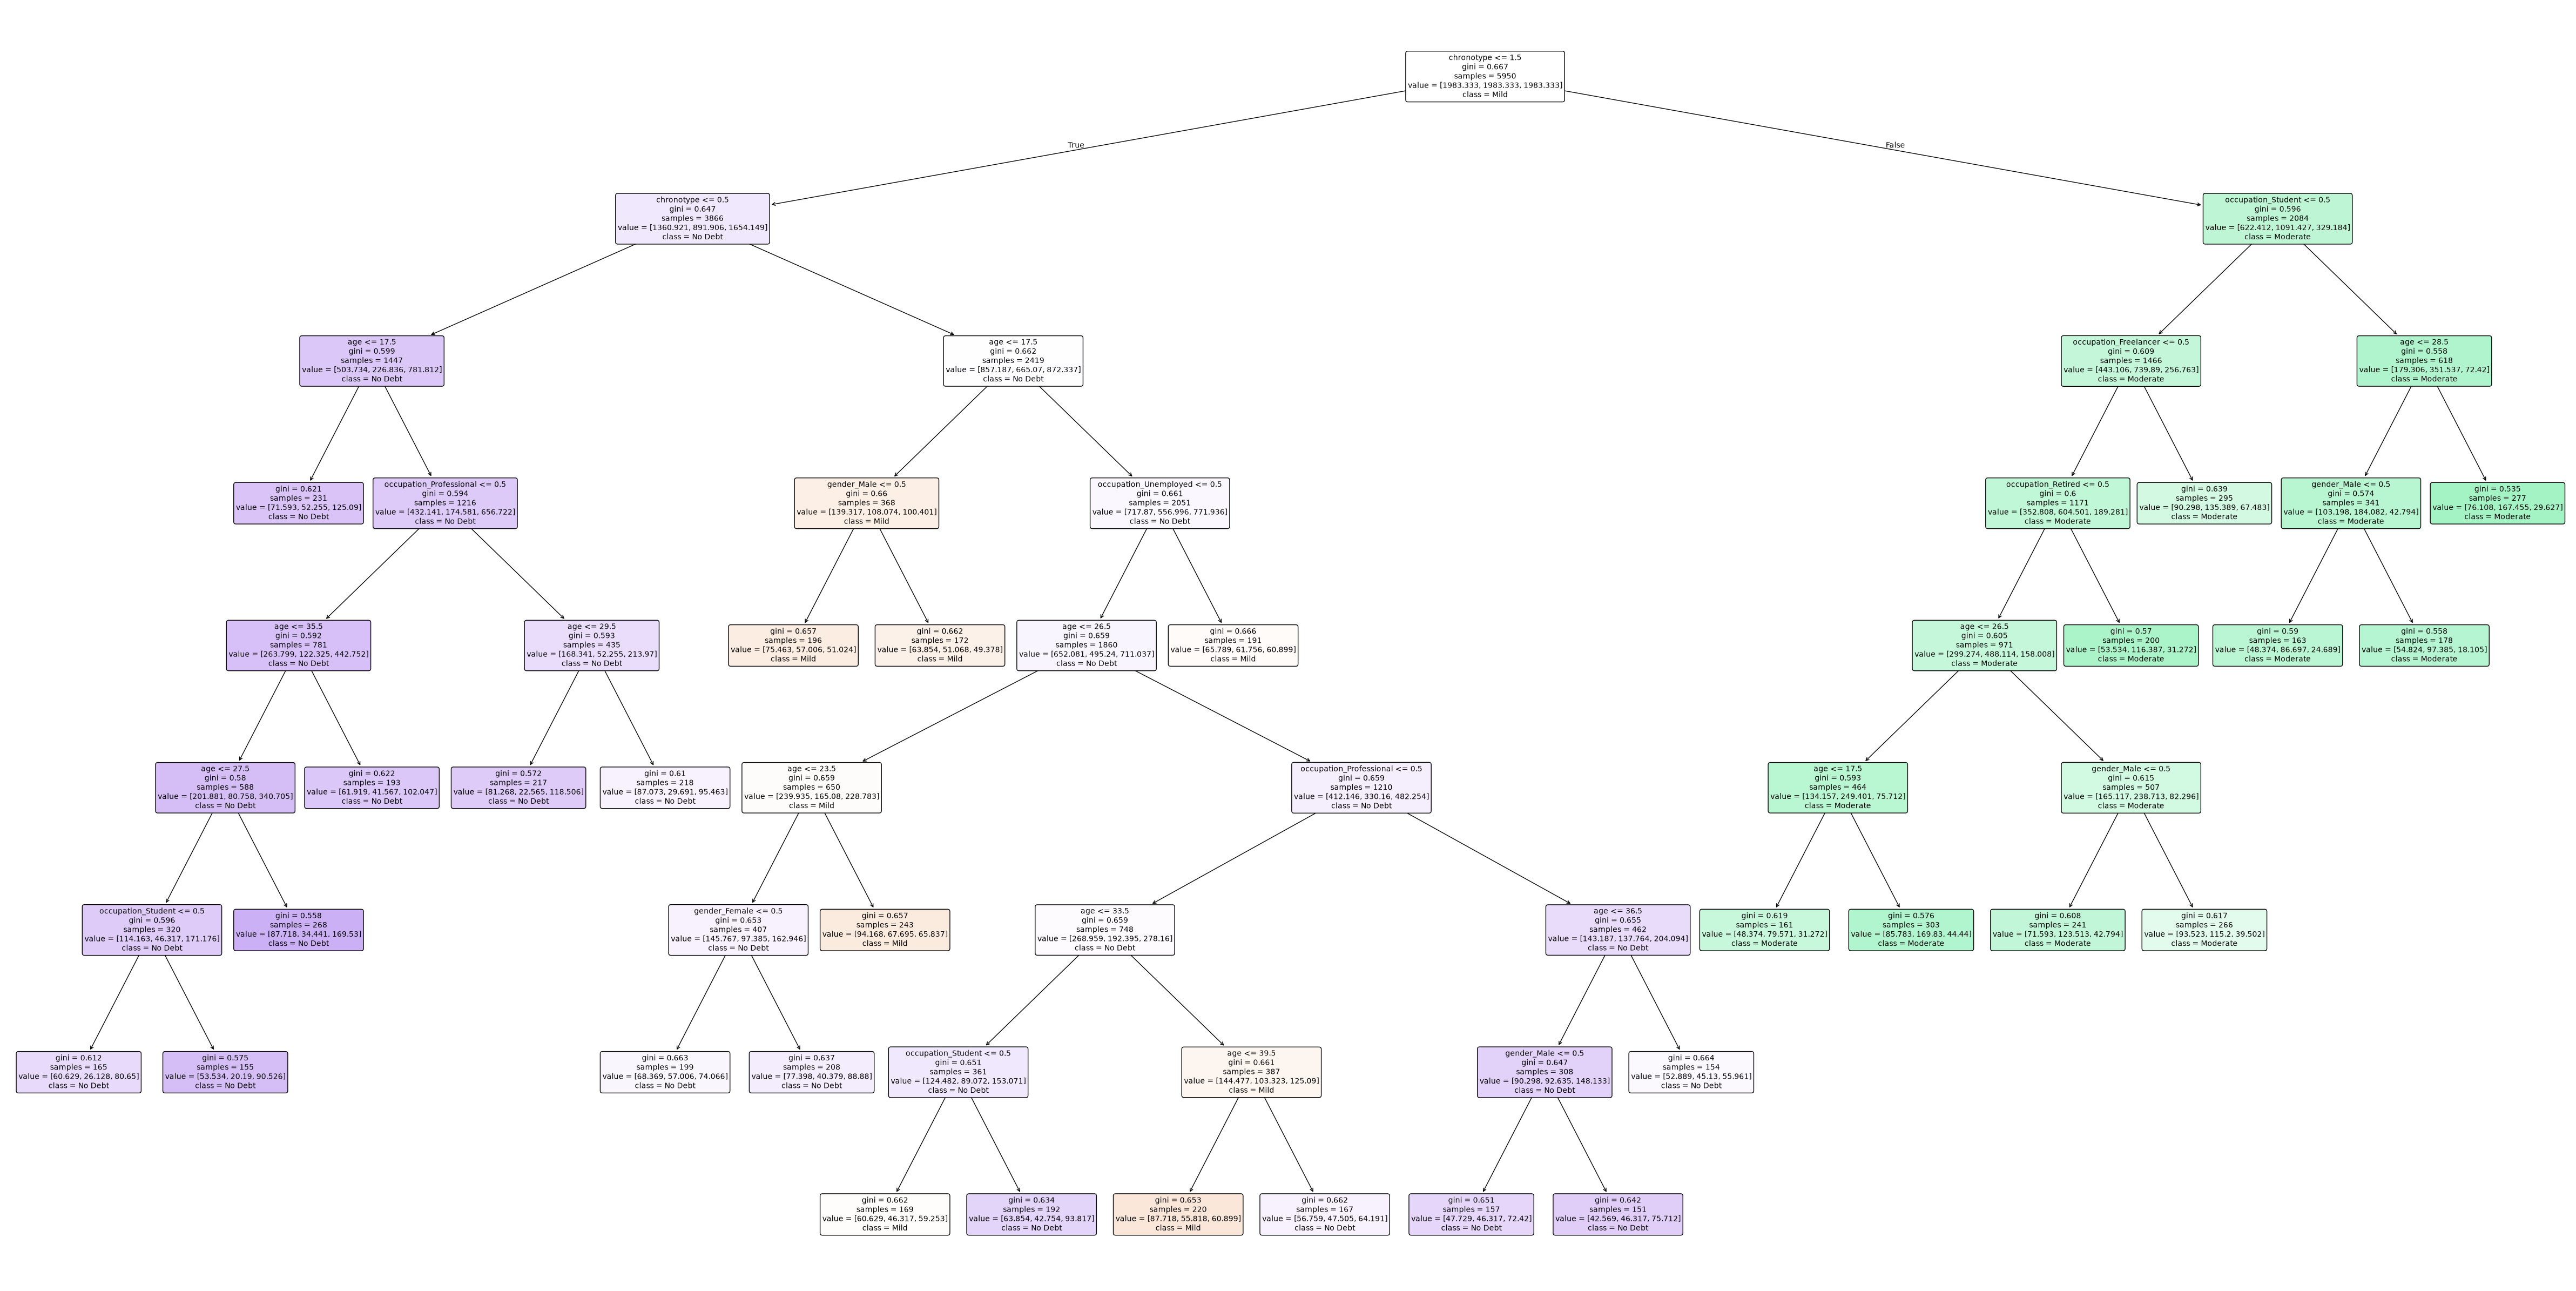

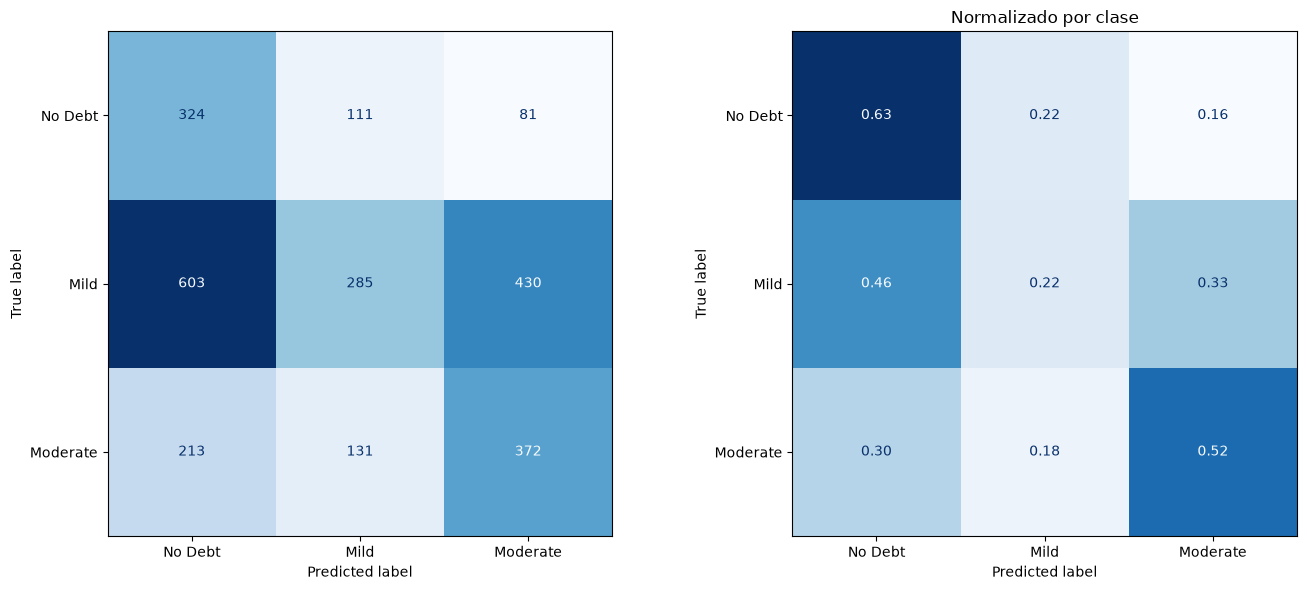

              precision    recall  f1-score   support

     No Debt       0.28      0.63      0.39       516
        Mild       0.54      0.22      0.31      1318
    Moderate       0.42      0.52      0.47       716

    accuracy                           0.38      2550
   macro avg       0.42      0.45      0.39      2550
weighted avg       0.46      0.38      0.37      2550



In [54]:
#Columnas con los datos que usaremos para la clasificación
X = df[["gender", "chronotype","occupation","age"]].copy() 
X["chronotype"] = X["chronotype"].map({"Early Bird": 0, "Intermediate": 1, "Night Owl": 2}) #Pasamos los valores de categóricos a numerales ordenados
X = pd.get_dummies(X, columns=["gender","occupation"]) 
y = df["sleep_debt_category"]

#Una vez definidas las categorías en las que clasificar y los criterios que se tomarán en cuenta, podemos crear el árbol


#Dividimos en test y entrenamiento
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=3, stratify=y
)


tree = DecisionTreeClassifier(
    criterion="gini",
    max_depth=8,
    class_weight="balanced",
    min_samples_leaf=150,
    random_state=6769420,
)

tree.fit(X_train, y_train)
pred = tree.predict(X_test)



fig, ax = plt.subplots(figsize=(48, 24))
plot_tree(
    tree,
    feature_names=X.columns,
    class_names=[str(c) for c in tree.classes_],
    filled=True, rounded=True, fontsize=10, ax=ax,
)
plt.tight_layout()



#################################################3
#Matriz de confusión

cm = confusion_matrix(y_test, pred, labels=["No Debt", "Mild", "Moderate"])

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

ConfusionMatrixDisplay.from_predictions(y_test, pred, labels=order, ax=axes[0], cmap="Blues", colorbar=False)

ConfusionMatrixDisplay.from_predictions(
    y_test, pred, labels=order, normalize="true", values_format=".2f",
    ax=axes[1], cmap="Blues", colorbar=False
)
axes[1].set_title("Normalizado por clase")

plt.tight_layout()
plt.show()

print(classification_report(y_test, pred, labels=order, zero_division=0))

plt.show()